# Compare backend performance on k8s (k6)

Compares the `filter_prices_duration` metric (time spent in `POST /cars/findByFilter` across 421 price ranges) for every backend, all deployed side by side on the same k3d cluster and hit through the same Traefik ingress.

## How measurements are done

Bring the cluster + all backends up:
```bash
cd ~/prj/vscar/k8s
make all
```

Run the k6 suite against every backend (`nestjs`, `fastapi`, `gin`, `rocket`, `ktor`, `spring`) via the ingress at `http://localhost:8080/{backend}`:
```bash
cd ~/prj/vscar/tests/k6
make test-k8s
```

This writes one `--summary-export` JSON file per backend to `data/k8s/{backend}.json`, each containing the aggregated `filter_prices_duration` stats (avg/min/med/max/p90/p95) for that run.

After that, run this notebook.

In [2]:
import json
from pathlib import Path

import pandas as pd
import seaborn as sns

folder = Path("data/k8s")
assert folder.exists() and folder.is_dir()  # noqa: PT018, S101
result_files = sorted(folder.glob("*.json"))
assert result_files, f"No result files found in {folder}. Run 'make test-k8s' first."  # noqa: S101

rows = []
for path in result_files:
    backend = path.stem
    values = json.loads(path.read_text())["metrics"]["filter_prices_duration"]
    for stat, value in values.items():
        rows.append({"backend": backend, "stat": stat, "duration_ms": value})

df = pd.DataFrame(rows)
df.head()

,backend,stat,duration_ms
0,fastapi,min,1.093581
1,fastapi,med,115.495759
2,fastapi,max,346.274104
3,fastapi,p(90),258.595005
4,fastapi,p(95),285.057305


## filter_prices_duration summary table

Backends sorted fastest to slowest by average duration.

In [3]:
table = df.pivot(index="backend", columns="stat", values="duration_ms")
table = table[[c for c in ["avg", "min", "med", "max", "p(90)", "p(95)"] if c in table.columns]]
table = table.sort_values("avg")
table

stat,avg,min,med,max,p(90),p(95)
backend,,,,,,
gin,23.308207,0.593289,24.394300,76.996630,41.211845,46.153219
rocket,24.700727,0.722381,23.374750,83.665566,47.378942,53.389811
ktor,28.005329,3.431492,22.400382,266.121930,35.398920,43.692984
spring,31.267454,2.174397,26.080489,144.456579,53.704657,75.175052
nestjs,104.590598,4.593247,101.018626,329.311455,202.738962,227.130534
fastapi,122.031868,1.093581,115.495759,346.274104,258.595005,285.057305


## Chart

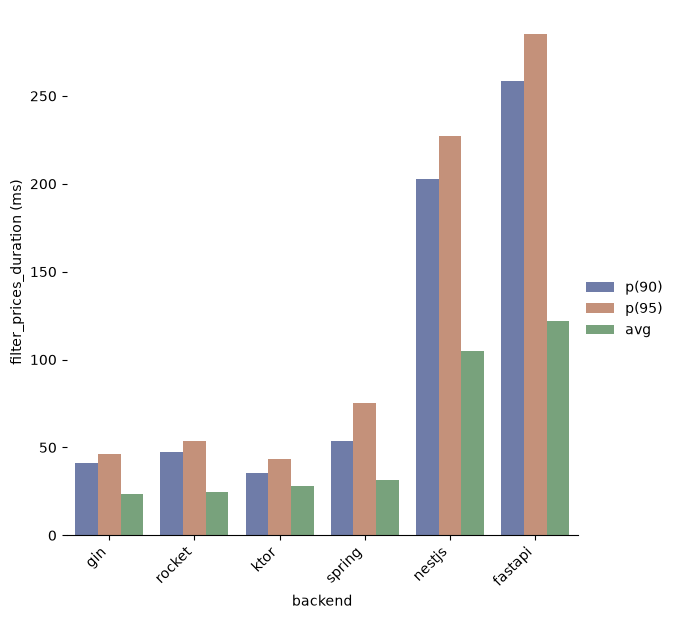

In [4]:
order = table.index.tolist()
plot_df = df[df["stat"].isin(["avg", "p(90)", "p(95)"])]

g = sns.catplot(
    data=plot_df,
    kind="bar",
    x="backend",
    y="duration_ms",
    hue="stat",
    order=order,
    palette="dark",
    alpha=0.6,
    height=6,
)
g.despine(left=True)
g.set_axis_labels("backend", "filter_prices_duration (ms)")
g.legend.set_title("")
g.set_xticklabels(rotation=45, ha="right")